# Customer Shopping Behavior Analysis

This notebook loads the raw retail dataset, audits data quality, creates an analysis-ready dataset, and explores the customer and product patterns used in the Power BI dashboard and project report.


## Business Question

How can the company use customer shopping data to identify trends, improve customer engagement, and optimize marketing and product strategies?


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="deep")

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_path = project_root / "data" / "raw" / "customer_shopping_behavior.csv"
processed_path = project_root / "data" / "processed" / "customer_behavior_cleaned.csv"


## 1. Load the Dataset

In [2]:
df = pd.read_csv(raw_path)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()


Rows: 3,900 | Columns: 18


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


## 2. Initial Data Audit

In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})

print(f"Duplicate rows: {df.duplicated().sum():,}")
summary


Duplicate rows: 0


,dtype,missing,unique_values
Customer ID,int64,0,3900
Age,int64,0,53
Gender,object,0,2
Item Purchased,object,0,25
Category,object,0,4
Purchase Amount (USD),int64,0,81
Location,object,0,50
Size,object,0,4
Color,object,0,25
Season,object,0,4


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,NaN,NaN,NaN,1950.5,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,NaN,NaN,NaN,44.068462,15.207589,18.0,31.0,44.0,57.0,70.0
Gender,3900,2,Male,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Purchased,3900,25,Blouse,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3900,4,Clothing,1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase Amount (USD),3900.0,NaN,NaN,NaN,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
Location,3900,50,Montana,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,3900,4,M,1755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,3900,25,Olive,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3900,4,Spring,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean and Transform the Data

The cleaning workflow imputes missing ratings by category, standardizes field names, creates analysis fields, and removes a redundant promotion field.


In [5]:
clean = df.copy()

# Impute 37 missing review ratings using the median within each category.
clean["Review Rating"] = clean["Review Rating"].fillna(
    clean.groupby("Category")["Review Rating"].transform("median")
)

# Standardize column names.
clean.columns = clean.columns.str.lower().str.replace(" ", "_", regex=False)
clean = clean.rename(columns={"purchase_amount_(usd)": "purchase_amount"})

# Create quartile-based age groups.
clean["age_group"] = pd.qcut(
    clean["age"],
    q=4,
    labels=["Young Adults", "Adult", "Middle-aged", "Senior"],
)

# Convert stated purchase cadence into an approximate number of days.
frequency_days = {
    "Weekly": 7,
    "Bi-Weekly": 14,
    "Fortnightly": 14,
    "Monthly": 30,
    "Quarterly": 90,
    "Every 3 Months": 90,
    "Annually": 365,
}
clean["purchase_frequency_days"] = clean["frequency_of_purchases"].map(frequency_days)

# Promo code usage duplicates the discount flag for every record.
assert clean["discount_applied"].equals(clean["promo_code_used"])
clean = clean.drop(columns="promo_code_used")

assert clean.isna().sum().sum() == 0
assert clean["customer_id"].is_unique

clean.head()


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adults,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adults,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


In [6]:
processed_path.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(processed_path, index=False, encoding="utf-8")
print(f"Saved {len(clean):,} cleaned records to {processed_path.relative_to(project_root)}")


Saved 3,900 cleaned records to data\processed\customer_behavior_cleaned.csv


## 4. Key Performance Indicators

In [7]:
kpis = pd.Series({
    "customers": clean["customer_id"].nunique(),
    "observed_revenue": clean["purchase_amount"].sum(),
    "average_purchase": clean["purchase_amount"].mean(),
    "average_rating": clean["review_rating"].mean(),
    "subscriber_share_pct": clean["subscription_status"].eq("Yes").mean() * 100,
    "discount_share_pct": clean["discount_applied"].eq("Yes").mean() * 100,
})
kpis.round(2)


customers                 3900.00
observed_revenue        233081.00
average_purchase            59.76
average_rating               3.75
subscriber_share_pct        27.00
discount_share_pct          43.00
dtype: float64

## 5. Category and Customer Analysis

In [8]:
category_summary = (
    clean.groupby("category")
    .agg(
        customers=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        average_purchase=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean"),
    )
    .sort_values("revenue", ascending=False)
)
category_summary["revenue_share_pct"] = (
    category_summary["revenue"] / category_summary["revenue"].sum() * 100
)
category_summary.round(2)


,customers,revenue,average_purchase,average_rating,revenue_share_pct
category,,,,,
Clothing,1737,104264,60.03,3.72,44.73
Accessories,1240,74200,59.84,3.77,31.83
Footwear,599,36093,60.26,3.79,15.49
Outerwear,324,18524,57.17,3.75,7.95


In [9]:
age_summary = (
    clean.groupby("age_group", observed=False)
    .agg(
        customers=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        average_purchase=("purchase_amount", "mean"),
        average_previous_purchases=("previous_purchases", "mean"),
    )
    .sort_values("revenue", ascending=False)
)
age_summary.round(2)


,customers,revenue,average_purchase,average_previous_purchases
age_group,,,,
Young Adults,1028,62143,60.45,24.78
Middle-aged,986,59197,60.04,25.53
Adult,942,55978,59.42,25.24
Senior,944,55763,59.07,25.90


## 6. Discounts, Subscriptions, and Repeat Purchasing

In [10]:
discount_summary = (
    clean.groupby("discount_applied")
    .agg(
        customers=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        average_purchase=("purchase_amount", "mean"),
        average_previous_purchases=("previous_purchases", "mean"),
    )
)

subscription_summary = (
    clean.assign(repeat_buyer=clean["previous_purchases"].gt(5))
    .groupby("subscription_status")
    .agg(
        customers=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        average_purchase=("purchase_amount", "mean"),
        repeat_buyer_share=("repeat_buyer", "mean"),
    )
)

display(discount_summary.round(2))
display(subscription_summary.round(3))


,customers,revenue,average_purchase,average_previous_purchases
discount_applied,,,,
No,2223,133670,60.13,25.06
Yes,1677,99411,59.28,25.74


,customers,revenue,average_purchase,repeat_buyer_share
subscription_status,,,,
No,2847,170436,59.865,0.884
Yes,1053,62645,59.492,0.910


## 7. Visual Exploration

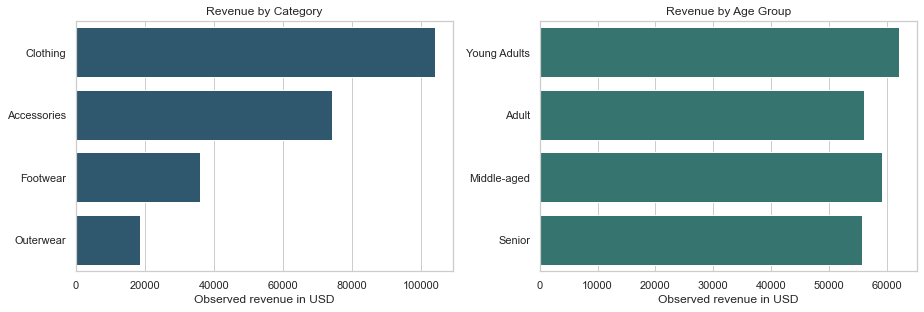

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(
    data=category_summary.reset_index(),
    x="revenue",
    y="category",
    color="#245B78",
    ax=axes[0],
)
axes[0].set_title("Revenue by Category")
axes[0].set_xlabel("Observed revenue in USD")
axes[0].set_ylabel("")

sns.barplot(
    data=age_summary.reset_index(),
    x="revenue",
    y="age_group",
    color="#2A7F78",
    ax=axes[1],
)
axes[1].set_title("Revenue by Age Group")
axes[1].set_xlabel("Observed revenue in USD")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


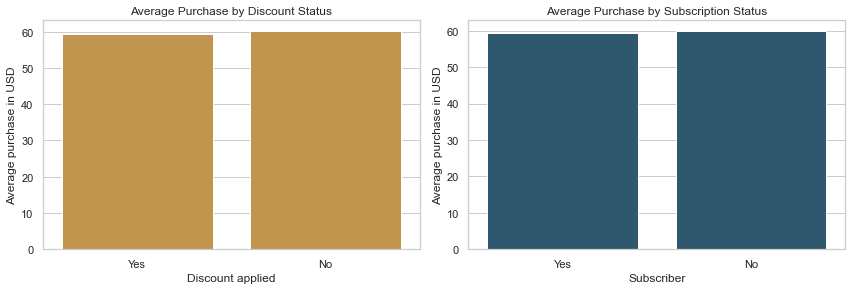

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.barplot(
    data=clean,
    x="discount_applied",
    y="purchase_amount",
    ci=None,
    color="#D49A3A",
    ax=axes[0],
)
axes[0].set_title("Average Purchase by Discount Status")
axes[0].set_xlabel("Discount applied")
axes[0].set_ylabel("Average purchase in USD")

sns.barplot(
    data=clean,
    x="subscription_status",
    y="purchase_amount",
    ci=None,
    color="#245B78",
    ax=axes[1],
)
axes[1].set_title("Average Purchase by Subscription Status")
axes[1].set_xlabel("Subscriber")
axes[1].set_ylabel("Average purchase in USD")

plt.tight_layout()
plt.show()


## 8. Main Findings

- Clothing generates the most revenue because it has the largest customer volume; category average purchases remain close to $60.
- Young Adults generate the highest age-group revenue, although average purchase values differ only slightly across age groups.
- Discounted records do not show a higher average purchase amount in this snapshot.
- Subscribers have a slightly higher repeat-buyer share but not a higher current average purchase.
- Ratings and previous-purchase counts have very weak correlations with current purchase amount.

These findings are descriptive. Controlled experiments and dated transaction data are needed before making causal claims.
